# 03 — K-Means (user segmentation)

Clusters from engagement features; `k` chosen via silhouette.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from corevent_analytics.config import get_settings
from corevent_analytics.data import load_data, build_user_features
from corevent_analytics.models import run_kmeans

sns.set_theme(style="whitegrid")
settings = get_settings()
tables, source = load_data(settings)
features = build_user_features(tables)
result = run_kmeans(
    features,
    k_max=settings.kmeans_k_max,
    random_state=settings.random_state,
)
print("source:", source)
result["metrics"]

source: postgres


{'n_clusters': 8,
 'inertia': 465.90127145414687,
 'silhouette': 0.27596746584670795}

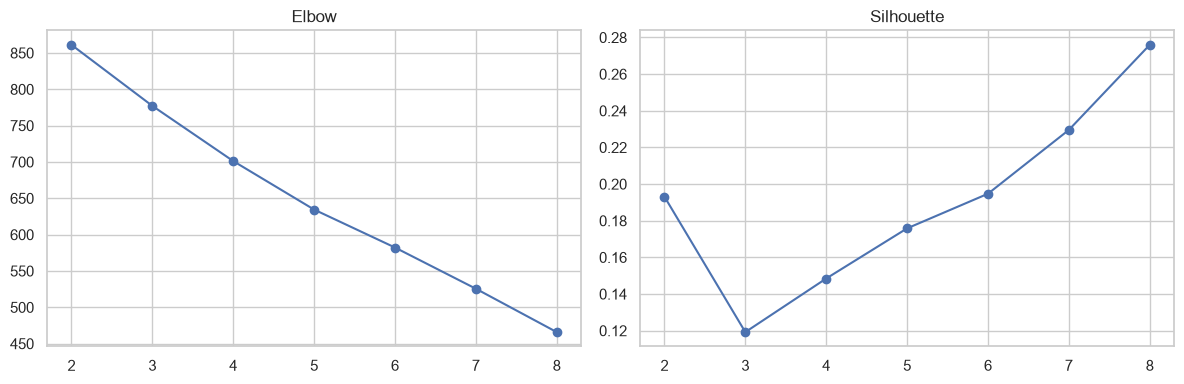

,age,account_age_days,n_orders,total_spent,avg_ticket,n_favorites,n_tickets,checkin_rate,cat_music,cat_sports,...,cat_education,cat_art_culture,cat_gastronomy,cat_health_wellness,cat_family_kids,cat_religious_spiritual,cat_games,cat_community_social,cat_fashion_beauty,cat_other
cluster,,,,,,,,,,,,,,,,,,,,,
0,38.245820,0.0,1.000000,55.714286,48.571429,3.0,1.142857,0.000000,0.428571,0.000000,...,0.000000,0.857143,0.500000,0.285714,0.142857,0.0,0.000000,0.000000,0.0,0.0
1,36.856947,0.0,1.000000,59.285714,51.071429,3.0,1.000000,0.000000,0.000000,0.571429,...,1.000000,0.000000,0.000000,0.285714,0.000000,0.0,0.000000,0.000000,0.0,0.0
2,36.269092,0.0,1.357143,99.242857,81.921429,3.0,1.785714,0.071429,0.571429,0.142857,...,0.142857,0.000000,0.285714,0.285714,0.000000,0.0,0.714286,0.571429,0.0,0.0
3,22.828200,0.0,1.000000,285.000000,285.000000,3.0,3.000000,0.111111,0.000000,0.666667,...,0.000000,0.666667,0.000000,0.000000,0.000000,0.0,0.333333,0.000000,1.0,0.0
4,43.345654,0.0,1.000000,135.000000,135.000000,3.0,3.000000,0.333333,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.0
5,35.266256,0.0,2.000000,160.750000,79.354167,3.0,2.375000,0.479167,0.125000,0.625000,...,0.250000,0.000000,0.500000,0.125000,0.625000,0.0,0.000000,0.250000,0.0,0.0
6,33.913073,0.0,0.000000,0.000000,0.000000,3.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.750000,0.000000,0.0,0.250000,0.000000,1.0,0.0
7,40.996578,0.0,2.000000,704.850000,352.425000,3.0,5.000000,0.000000,0.500000,0.000000,...,0.500000,0.000000,0.500000,0.000000,0.000000,0.0,1.000000,0.000000,0.0,0.0


In [2]:
selection = result["selection"]
if selection:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(selection["ks"], selection["inertias"], marker="o")
    axes[0].set_title("Elbow")
    axes[1].plot(selection["ks"], selection["silhouettes"], marker="o")
    axes[1].set_title("Silhouette")
    fig.tight_layout()
    plt.show()
result["centroids"]

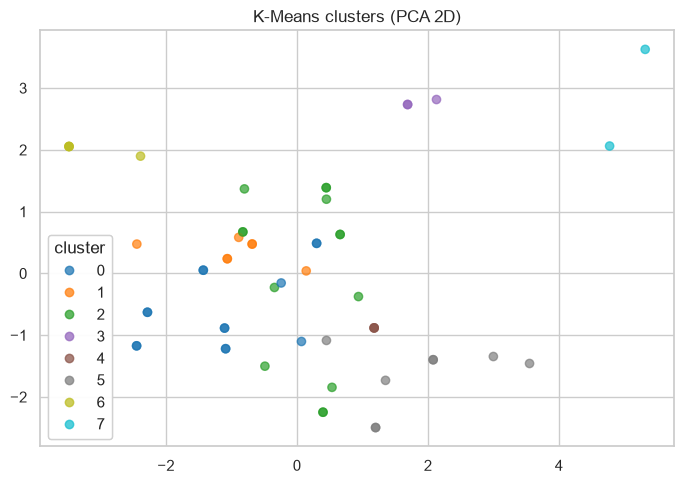

In [3]:
scaled = result.get("scaled_features")
labels = result.get("labels")
if scaled is not None and labels is not None and len(labels):
    pca = PCA(n_components=2, random_state=settings.random_state)
    xy = pca.fit_transform(scaled)
    fig, ax = plt.subplots(figsize=(7, 5))
    scatter = ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", alpha=0.7)
    ax.set_title("K-Means clusters (PCA 2D)")
    legend = ax.legend(*scatter.legend_elements(), title="cluster")
    ax.add_artist(legend)
    fig.tight_layout()
    plt.show()
else:
    print("Not enough data for PCA plot")